# Reading scalar fields in their original coordinates

A finite encoding lets us recover spaces and maps at original parameters. A numerical feature keeps a chosen part of that information. To interpret a picture of a feature, we need to know which coordinates, window and layer it uses.

This guide starts with a rectangular module whose answers we can predict. We will place its sampled line landscapes back in the parameter plane, inspect sections of a field with four coordinates, and compare compatible results on one scale. You need TamerOp, CairoMakie, basic arrays and the idea of a [finite encoding](../finite_encodings.md). The [ordinary-analysis guide](ordinary_analysis.ipynb) introduces the one-parameter transforms; the [API reference](../src/reference/visualization.md#coordinate-sections-of-scalar-fields) gives the precise controls.

In [1]:
import TamerOp as OP
using CairoMakie
const A = OP.Advanced
const QQ = Rational{BigInt}
V = OP.Visualization;

TamerOp.Visualization

## A rectangle gives a landscape we can check

Take the module that is one-dimensional on the square $[0,4)\times[0,4)$ and zero elsewhere, with identity maps inside the square. Four finite labels suffice: only the first carries a nonzero space. The grid assignment recovers the square in the original coordinates; it is not a point-cloud filtration.

A diagonal line through a point $(x,y)$ stays inside the square for a symmetric radius at most $\min(x,y,4-x,4-y)$. Where the point lies inside the square, this is the first diagonal landscape height. The second layer is zero because there is only one interval.

In [2]:
P = OP.FiniteFringe.ProductOfChainsPoset((2,2))
dims = [1,0,0,0]
maps = Dict(e => zeros(QQ,dims[e[2]],dims[e[1]]) for e in OP.FiniteFringe.cover_edges(P))
M = OP.Modules.PModule{QQ}(P,dims,maps;field=OP.CoreModules.QQField())
pi = OP.EncodingCore.GridEncodingMap(P,([0,4],[0,4]))
enc = OP.EncodingResult(P,M,pi)
OP.describe(enc)

(kind = :encoding_result, poset_type = TamerOp.FiniteFringe.ProductOfChainsPoset{2}, module_type = TamerOp.Modules.PModule{Rational{BigInt}, TamerOp.CoreModules.CoeffFields.QQField, Matrix{Rational{BigInt}}, TamerOp.FiniteFringe.ProductOfChainsPoset{2}}, encoding_map_type = TamerOp.EncodingCore.GridEncodingMap{2, Int64, TamerOp.FiniteFringe.ProductOfChainsPoset{2}}, compiled = false, backend = :auto, has_cohomology = false, has_presentation = false, module_dims = [1, 0, 0, 0], materialized = true, provenance = (category = :finite_poset_representations, base_poset = ProductOfChainsPoset(axes=(2, 2), nvertices=4), field = TamerOp.CoreModules.CoeffFields.QQField(), degree = nothing, degree_convention = :not_applicable, encoding = (map_type = TamerOp.EncodingCore.GridEncodingMap{2, Int64, TamerOp.FiniteFringe.ProductOfChainsPoset{2}}, backend = :auto), window = :not_recorded, orientation = :not_recorded, construction = (requested = :not_recorded, effective = :not_recorded, substitution = :

The requested diagonal direction is normalized by the landscape workflow to $(1/2,1/2)$. With offsets along the second coordinate, its stored parameterization is $x(t)=(0,b)+t(1/2,1/2)$. We retain a common parameter window and a half-unit evaluation grid. The line barcode computation resolves the encoding changes; the landscape grid is a separate sampling choice.

In [3]:
offsets = collect(-4.:0.5:4.)
tgrid = collect(-8.:0.5:16.)
L = OP.mp_landscape(enc; directions=[[1.,1.]], offsets=[(0.,b) for b in offsets],
    tgrid=tgrid, ts=tgrid, kmax=2)
OP.mp_landscape_summary(L)

(kind = :mp_landscape, ndirections = 1, noffsets = 17, kmax = 2, grid_length = 49, values_shape = (1, 17, 2, 49), weight_shape = (1, 17), total_weight = 1.0, t_range = (-8.0, 16.0), weights_normalized = true)

## Put each sample where it belongs

A stack indexed by direction and offset is not yet a field on the parameter plane. `ambient_landscape` requires the actual basepoints and source window. It interpolates only along stored lines, rescales heights using the declared direction, and leaves locations on unstored lines unavailable. Slice weights do not change these pointwise heights.

The square uses critical times on our grid, so its first-layer tents can be checked directly. The numerical interpolation bound is conditional on the stated error of the retained samples; it does not certify an earlier discretization or a statistical confidence band.

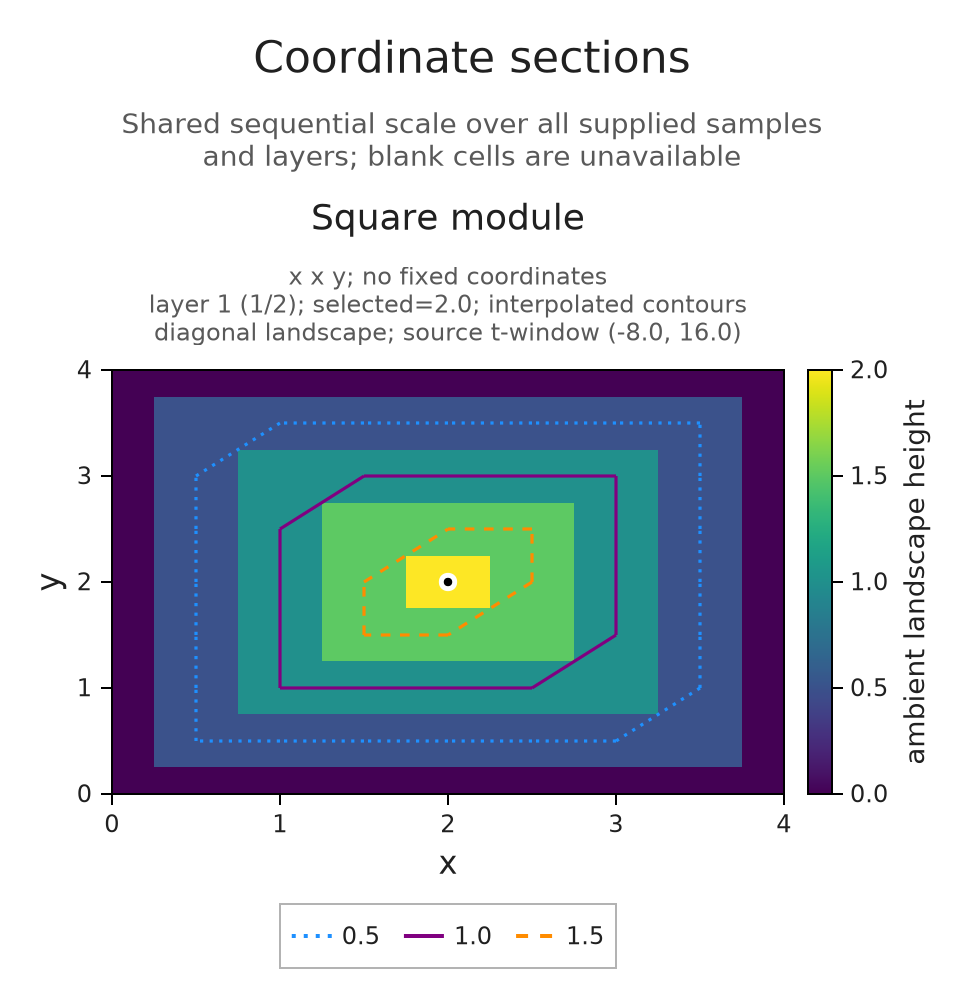

In [4]:
grid = collect(0.:0.5:4.)
g = OP.ambient_landscape(L; axes=(grid,grid), basepoints=[(0.,b) for b in offsets],
    source_window=(-8.,16.), sample_error=0.)
expected = [max(0.,min(x,y,4-x,4-y)) for x in grid,y in grid]
@assert A.landscape_values(g)[:,:,1] ≈ expected
@assert all(iszero,A.landscape_values(g)[:,:,2])
f = OP.ScalarField(g;id="Square module",axis_labels=("x","y"))
OP.visualize(f;layer="1",contours=[0.5,1.,1.5],backend=:cairomakie)

The contour curves belong to the piecewise-affine interpolation of these values. They are useful for reading heights. They are not a newly computed support boundary or a decomposition of the module.

Selecting the second layer preserves the color scale. A uniformly zero panel now has its intended meaning: the second landscape height is zero everywhere in this sampled window.

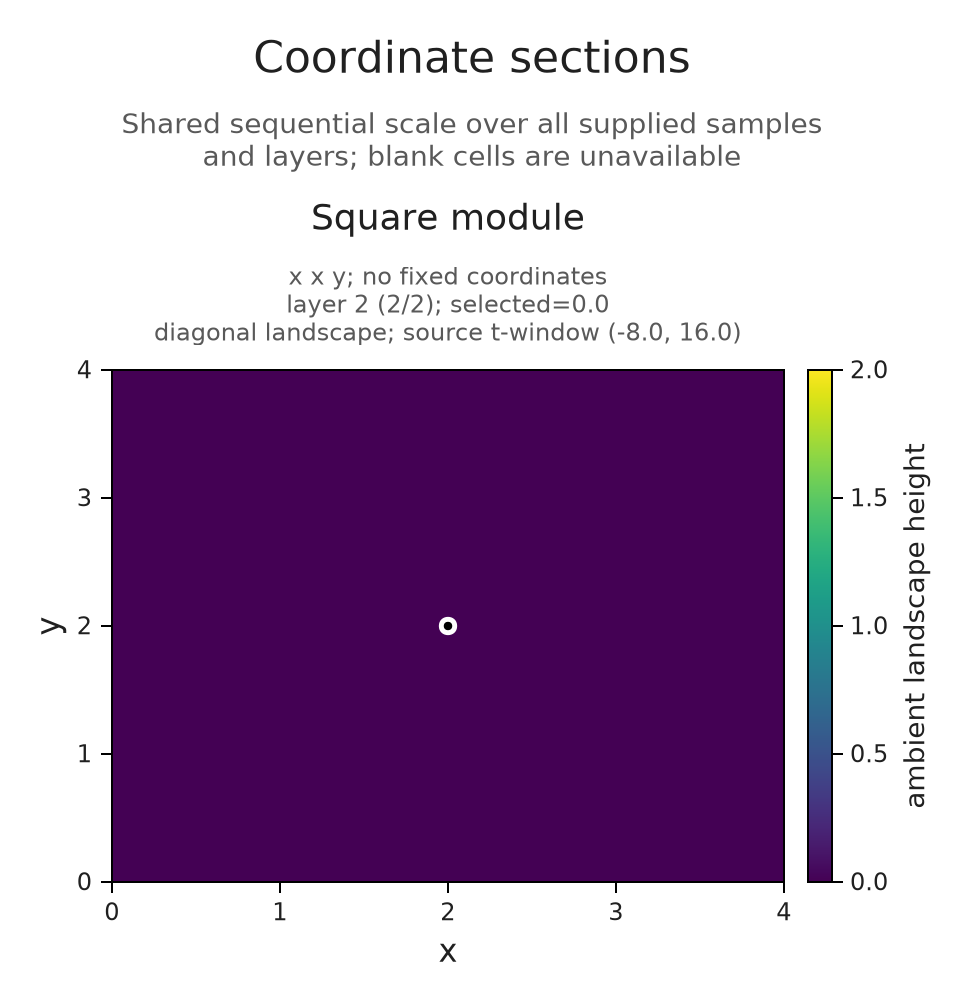

In [5]:
OP.visualize(f;layer="2",backend=:cairomakie)

## A plane inside four coordinates

The same display contract applies to other scalar invariants evaluated on a Cartesian grid. Supply actual coordinate values and axis labels, with the values array ordered by those axes. We use $F(a,b,c,d)=a+2b-c+d$ so that every displayed sample can be checked without a hidden invariant computation. `ScalarField` records supplied values; it does not construct an encoding.

A selected point supplies the fixed coordinates for every plane. In the first panel below, the horizontal coordinate is $c$ and the vertical coordinate is $a$. The other two coordinates remain $b=0$ and $d=9$.

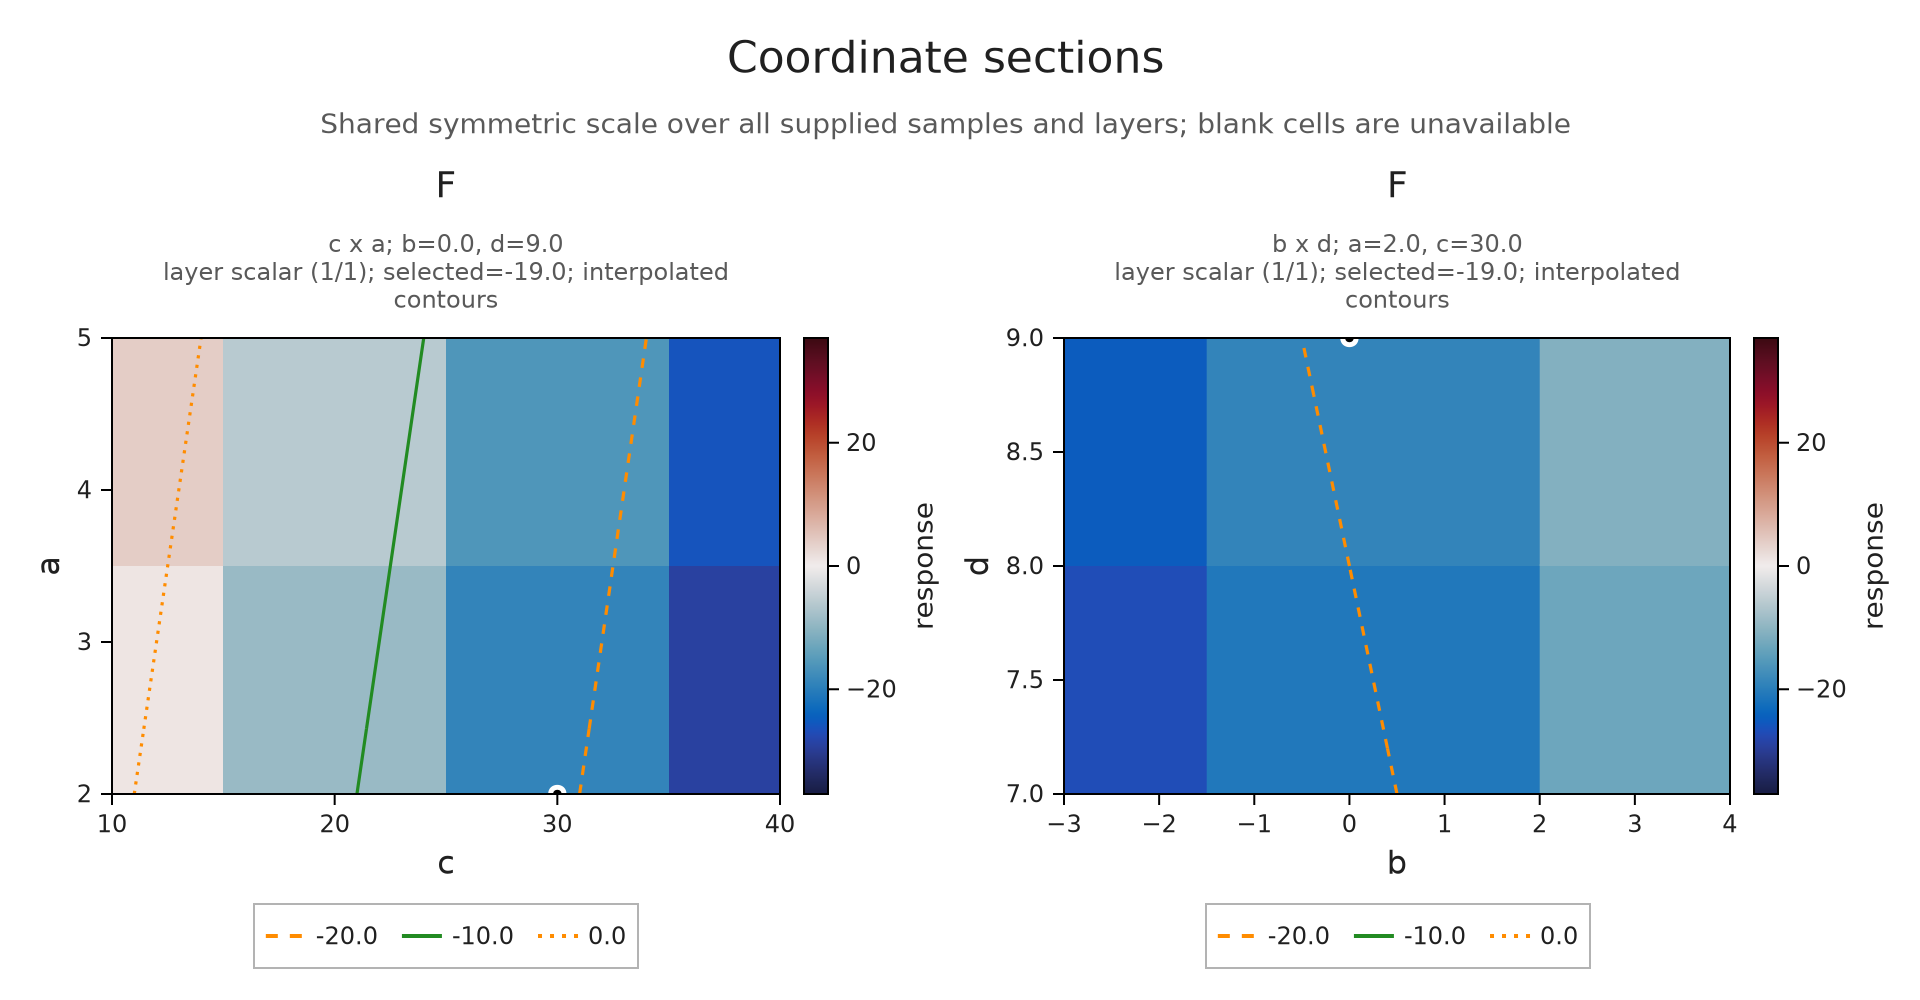

In [6]:
axes4 = ([2.,5.],[-3.,0.,4.],[10.,20.,30.,40.],[7.,9.])
values = [a+2b-c+d for a in axes4[1],b in axes4[2],c in axes4[3],d in axes4[4]]
field = OP.ScalarField(axes4,values;id="F",axis_labels=("a","b","c","d"),units="response")
session = OP.field_session(field;planes=[(3,1),(2,4)],indices=(1,2,3,2),contours=[-20.,-10.,0.])
OP.visualize(A.inspection_snapshot(session);backend=:cairomakie)

At the selected point $(2,0,30,9)$, the value is $2+0-30+9=-19$. Moving the second coordinate changes the first plane because that coordinate was held fixed there. In the second plane it moves the selection through an already displayed axis.

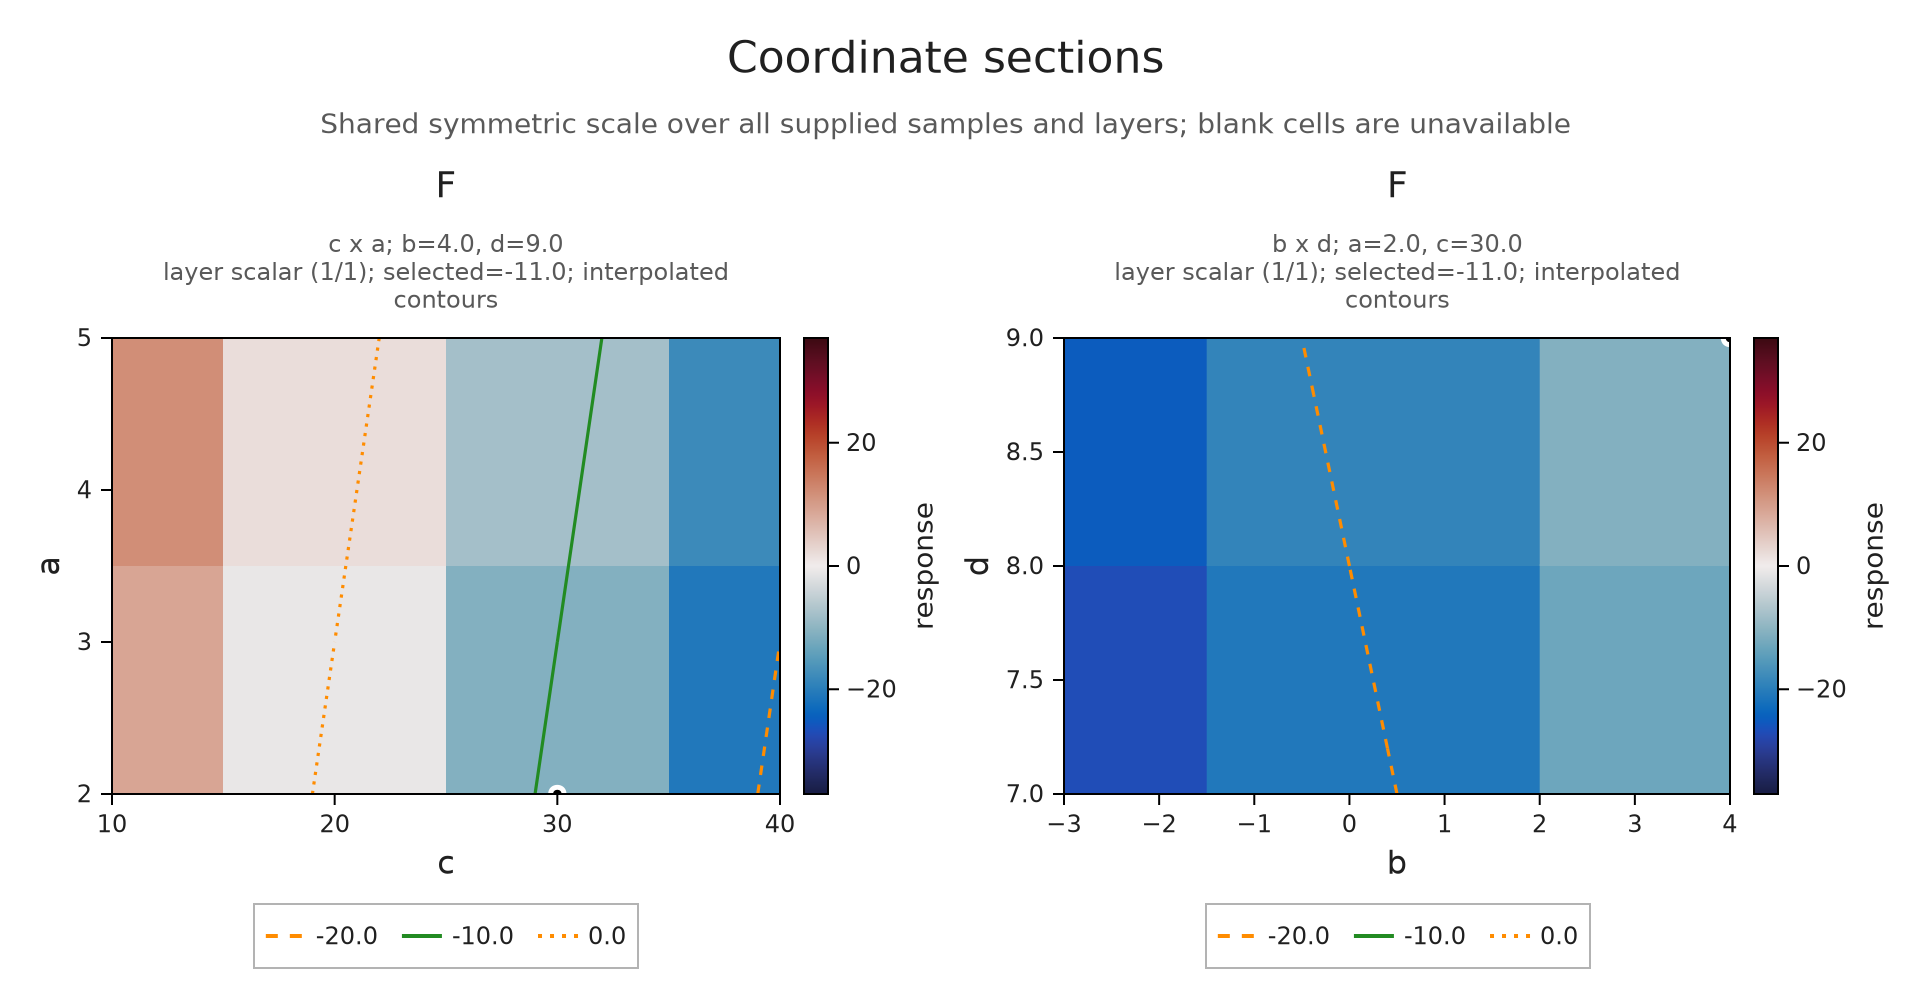

In [7]:
@assert all(row.value == -19 for row in A.inspection_summary(session).selected_values)
scale_before = A.inspection_summary(session).scale
A.select_inspection!(session;indices=(1,3,3,2))
@assert all(row.value == -11 for row in A.inspection_summary(session).selected_values)
@assert A.inspection_summary(session).scale == scale_before
OP.visualize(A.inspection_snapshot(session);backend=:cairomakie)

## Compare values through a declared correspondence

Passing several fields together declares that their identical axes, labels, units and ordered layers represent the same parameters. Distinct field IDs survive changes of plane and selection. For unrelated finite-poset labels, use the [comparison guide](comparisons.ipynb) to state the correspondence instead.

Here $G=F+3$, so subtracting the baseline F must give a constant 3 for G and zero for F. The difference has a shared scale centered at zero. Missing samples would remain blank in either difference.

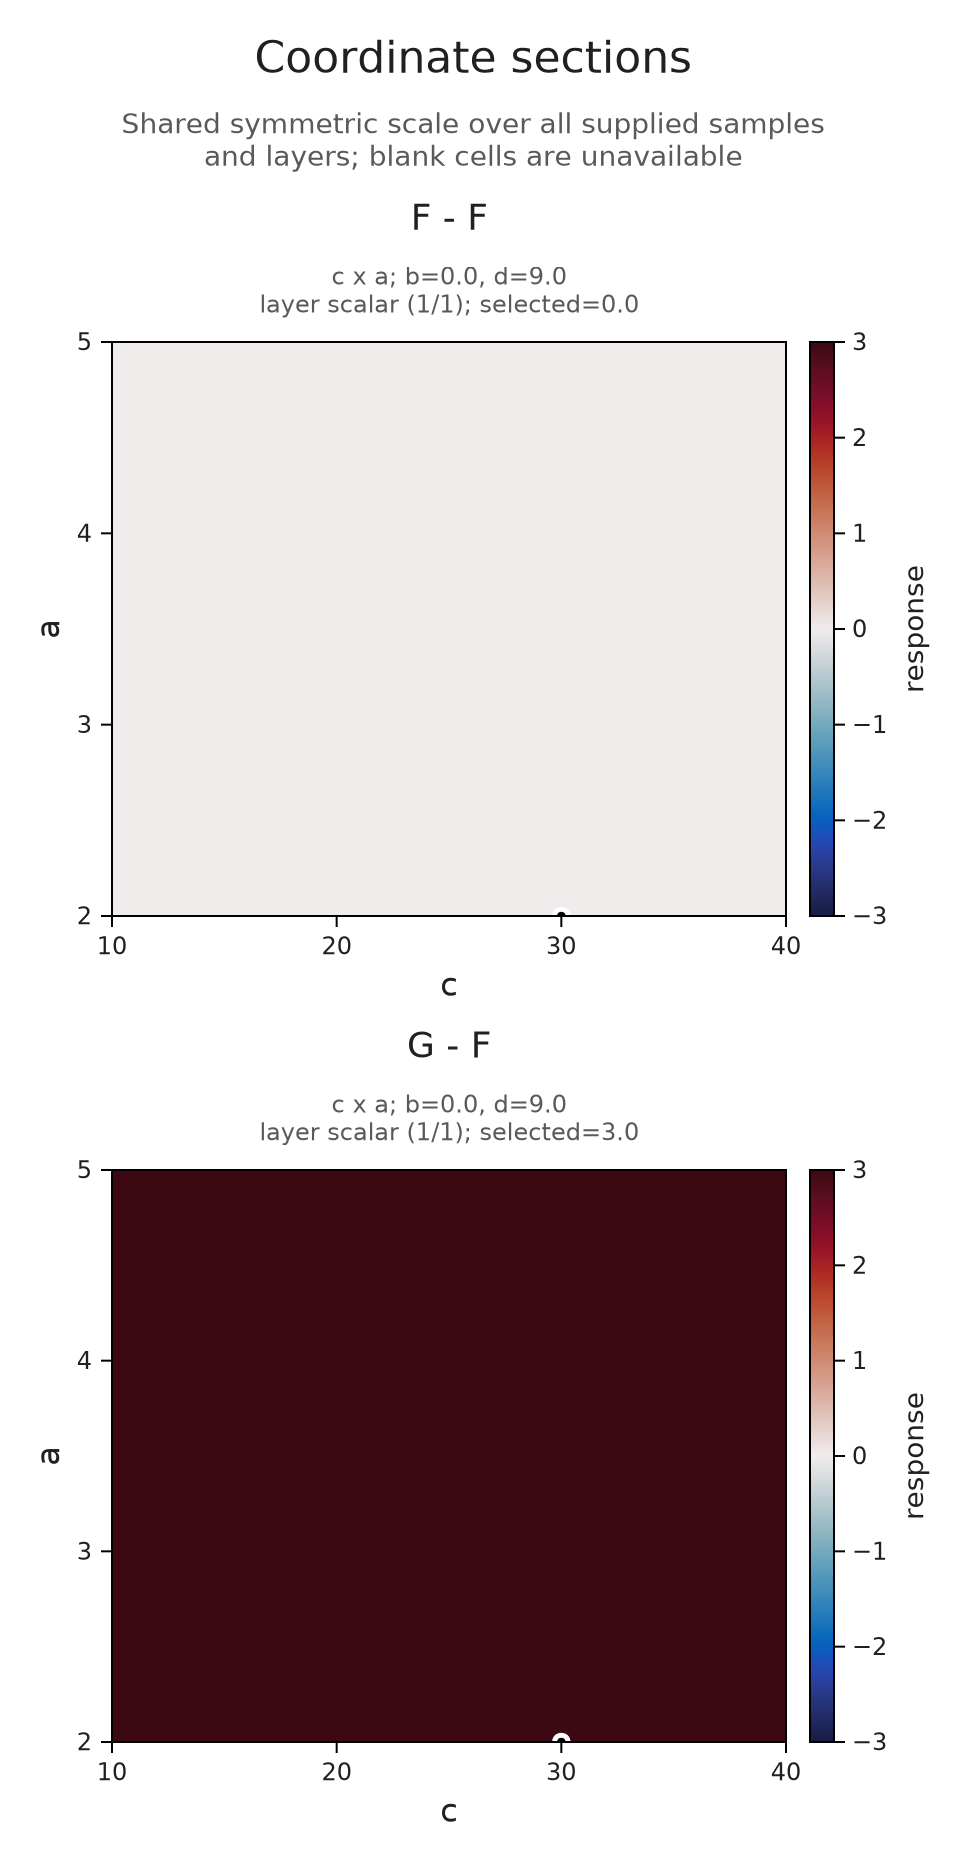

In [8]:
other = OP.ScalarField(axes4,values .+ 3;id="G",axis_labels=("a","b","c","d"),units="response")
comparison = OP.field_session([field,other];planes=[(3,1)],indices=(1,2,3,2),baseline="F")
@assert A.inspection_summary(comparison).scale.limits == (-3.,3.)
OP.visualize(A.inspection_snapshot(comparison);backend=:cairomakie)

### Try another section

Change the selected plane to $(d,b)$ and predict the selected value at $(a,b,c,d)=(5,-3,20,7)$. Does exchanging the horizontal and vertical axes change the scalar answer?

In [9]:
A.select_inspection!(session;planes=[(4,2)],indices=(2,1,2,1))
@assert only(A.inspection_summary(session).selected_values).value == -14
A.select_inspection!(session;planes=[(2,4)])
@assert only(A.inspection_summary(session).selected_values).value == -14
A.inspection_selection(session)

(planes = ((2, 4),), indices = (2, 1, 2, 1), layer = "scalar", normalization = :auto, colorrange = nothing, contours = (-20.0, -10.0, 0.0), baseline = nothing, max_cells = 250000, revision = 3)

### Optional: query a barcode through a selected point

A scalar field does not retain the module's structure maps. To ask for a slice barcode, return to the original encoding. Here a three-coordinate cube module is one-dimensional on $[0,4)^3$. Its sampled dimension field supplies a selected point, and the encoding supplies the maps along the requested line.

At $(1,2,3)$ the line $x(t)=(1,2,3)+t(1,1,1)$ enters the cube at $t=-1$ and leaves it at $t=1$, so its barcode is one interval with those endpoints. Unlike `mp_landscape`'s initial direction sampling, this direct query uses the explicitly supplied direction $(1,1,1)$. The returned endpoints are line-parameter values.

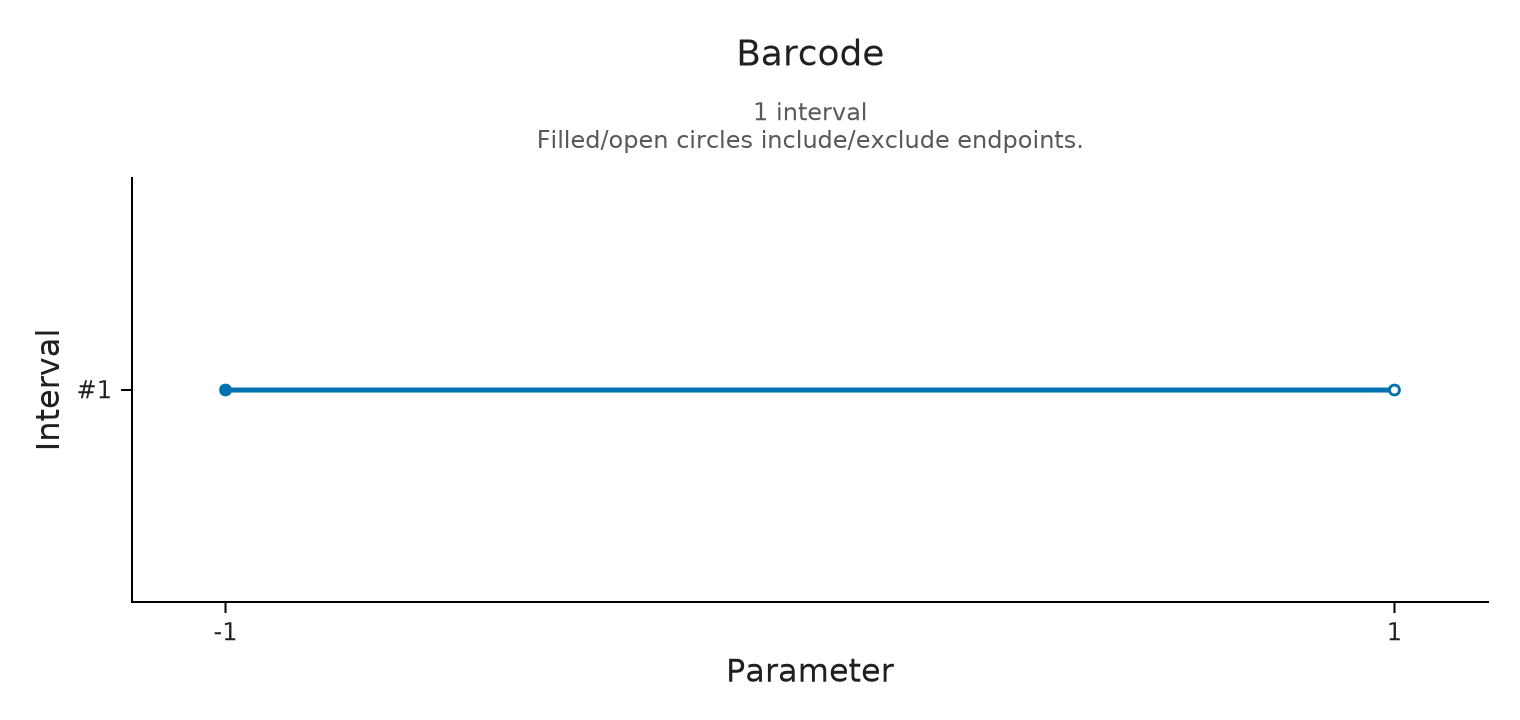

In [10]:
P3 = OP.FiniteFringe.ProductOfChainsPoset((2,2,2))
dims3 = [1; zeros(Int,7)]
maps3 = Dict(e => zeros(QQ,dims3[e[2]],dims3[e[1]]) for e in OP.FiniteFringe.cover_edges(P3))
M3 = OP.Modules.PModule{QQ}(P3,dims3,maps3;field=OP.CoreModules.QQField())
pi3 = OP.EncodingCore.GridEncodingMap(P3,([0,4],[0,4],[0,4]))
enc3 = OP.EncodingResult(P3,M3,pi3)
grid3 = collect(0.:4.)
dimensions3 = [dims3[A.locate(pi3,(x,y,z))] for x in grid3,y in grid3,z in grid3]
cube = OP.ScalarField((grid3,grid3,grid3),dimensions3;id="Cube dimensions",units="dimension")
cube_session = OP.field_session(cube;indices=(2,3,4))
selected = Tuple(grid3[i] for i in A.inspection_selection(cube_session).indices)
bars = OP.slice_barcode(enc3;directions=[[1.,1.,1.]],offsets=[selected],ts=collect(-4.:4.))
@assert bars == Dict((-1.,1.)=>1)
A.close_inspection!(cube_session)
OP.visualize(bars;kind=:barcode,backend=:cairomakie)

### Optional: distinguish a hole in sampling from zero

Keeping only the central diagonal does not supply the rest of the plane. The adapter refuses to fill those locations by extrapolating across lines. This distinction matters whenever a smooth-looking figure might suggest more information than was computed.

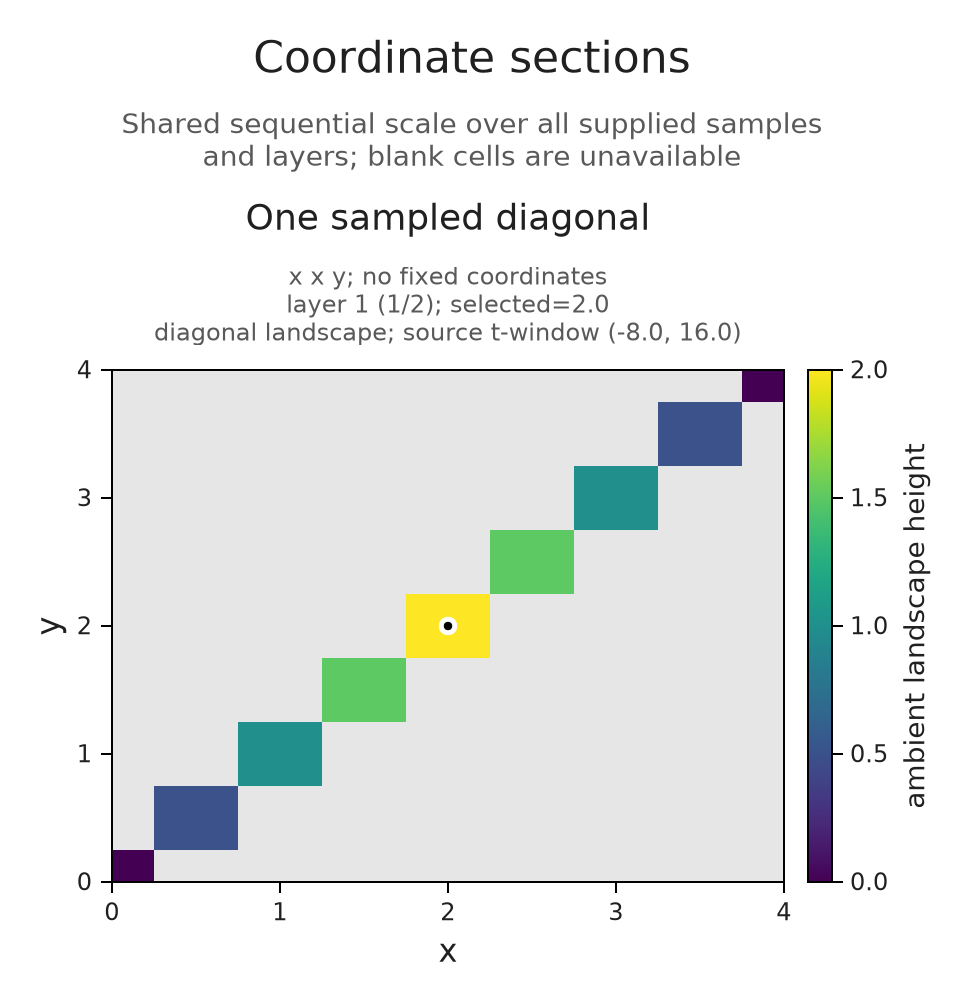

In [11]:
middle = findfirst(==(0.),offsets)
one_line = A.MPLandscape(2,copy(tgrid),copy(L.values[:,middle:middle,:,:]),ones(1,1),copy(A.slice_directions(L)),[(0.,0.)])
sparse_grid = OP.ambient_landscape(one_line;axes=(grid,grid),basepoints=[(0.,0.)],source_window=(-8.,16.))
@assert OP.describe(sparse_grid).covered == length(grid)
OP.visualize(OP.ScalarField(sparse_grid;id="One sampled diagonal",axis_labels=("x","y"));backend=:cairomakie)

### Optional: open the linked controls

With WGLMakie installed, `using WGLMakie; OP.visualize(session; backend=:wglmakie)` opens controls while Julia is running. Coordinate sliders, plane and layer entries, and chart clicks update every view of the same session. A chart click selects the nearest stored grid point; it does not evaluate the invariant at an arbitrary continuous point. Use the index controls for a precise stored selection.

A saved static snapshot records its fixed coordinates and scale. It does not retain Julia callbacks. [Session usage](live_inspection.ipynb) explains the lifecycle and the separately supported saved-state workflows.

In [12]:
final_view = A.inspection_snapshot(session)
A.close_inspection!(session)
A.close_inspection!(comparison)
@assert A.inspection_summary(session).closed
@assert A.check_visual_spec(final_view).valid
nothing

The next choice is how several compatible results become an experiment. Continue with [declared comparisons and collections](comparisons.ipynb). For the computational choices behind these fields, see [landscape sampling and ambient queries](../implementation/feature_transforms.md).